# 02 · Exploratory Data Analysis

Goal: understand the cleaned dataset before any modeling.
All data comes from `data/processed/pokemon.csv`, built by `python -m src.data.build_dataset`.

In [17]:
# Setup: let this notebook import from src/ (the notebook runs from notebooks/, src/ lives one level up)
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Python:", sys.executable)  # must end in pokelab\.venv\Scripts\python.exe

Python: c:\Users\singh\Projects\pokelab\.venv\Scripts\python.exe


In [18]:
import pandas as pd

from src.config import PROCESSED_DIR
from src.data.build_dataset import STAT_COLS  # same stat list the pipeline uses

df = pd.read_csv(PROCESSED_DIR / "pokemon.csv")
print(df.shape)
df.head()

(1025, 24)


,dex_id,name,species_slug,pokemon_slug,generation,type_1,type_2,hp,attack,defense,...,abilities,hidden_ability,evolves_from,is_legendary,is_mythical,sprite_url,artwork_url,form_override,evolution_stage,is_fully_evolved
0,1,Bulbasaur,bulbasaur,bulbasaur,1,grass,poison,45,49,49,...,overgrow,chlorophyll,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,False,1,False
1,2,Ivysaur,ivysaur,ivysaur,1,grass,poison,60,62,63,...,overgrow,chlorophyll,bulbasaur,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,False,2,False
2,3,Venusaur,venusaur,venusaur,1,grass,poison,80,82,83,...,overgrow,chlorophyll,ivysaur,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,False,3,True
3,4,Charmander,charmander,charmander,1,fire,NaN,39,52,43,...,blaze,solar-power,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,False,1,False
4,5,Charmeleon,charmeleon,charmeleon,1,fire,NaN,58,64,58,...,blaze,solar-power,charmander,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,https://raw.githubusercontent.com/PokeAPI/spri...,False,2,False


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

# One label per Pokémon: mythical > legendary > regular
df["category"] = np.select([df["is_mythical"], df["is_legendary"]], ["mythical", "legendary"], "regular")

## 1. What's in the dataset?

category
regular      931
legendary     71
mythical      23
Name: count, dtype: int64 

Dual-typed: 526 of 1025


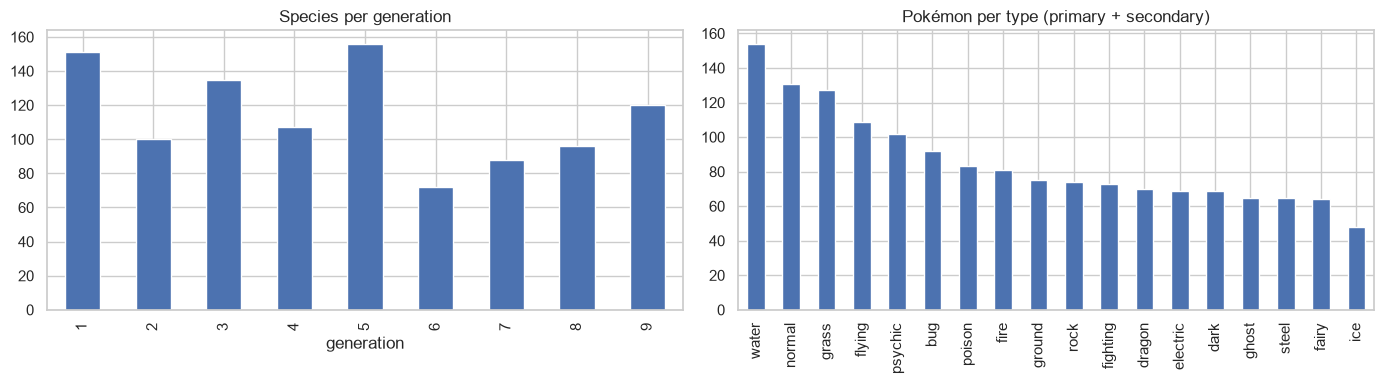

In [20]:
print(df["category"].value_counts(), "\n")
print("Dual-typed:", df["type_2"].notna().sum(), "of", len(df))

# A Pokémon counts once for each of its types
type_counts = pd.concat([df["type_1"], df["type_2"].dropna()]).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["generation"].value_counts().sort_index().plot.bar(ax=axes[0], title="Species per generation")
type_counts.plot.bar(ax=axes[1], title="Pokémon per type (primary + secondary)")
plt.tight_layout()

## 2. How are the six stats distributed?

Skew > 0 means a long right tail: a few Pokémon with very high values. Outliers matter because StandardScaler uses the mean and standard deviation, which outliers pull around.

,hp,attack,defense,sp_attack,sp_defense,speed,bst
count,1025.0,1025.0,1025.0,1025.0,1025.0,1025.0,1025.0
mean,70.2,77.7,72.6,70.2,70.3,67.2,428.3
std,26.6,29.8,29.3,29.7,26.7,28.7,112.8
min,1.0,5.0,5.0,10.0,20.0,5.0,180.0
25%,50.0,55.0,50.0,47.0,50.0,45.0,325.0
50%,68.0,75.0,70.0,65.0,67.0,65.0,452.0
75%,85.0,100.0,90.0,90.0,86.0,88.0,509.0
max,255.0,181.0,230.0,173.0,230.0,200.0,720.0


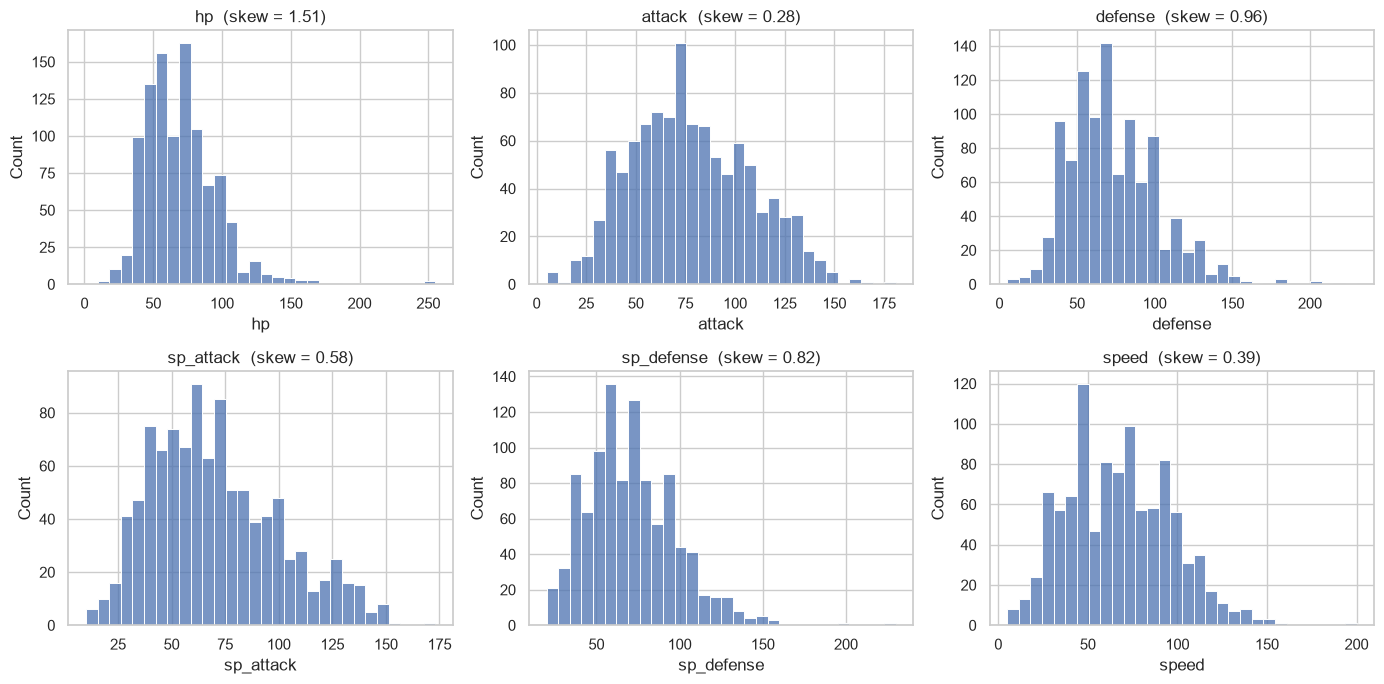

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, STAT_COLS):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
plt.tight_layout()

df[STAT_COLS + ["bst"]].describe().round(1)

In [22]:
# The most extreme Pokémon for each stat: are these real, or data problems?
for col in STAT_COLS:
    top = df.nlargest(3, col)[["name", col]].values.tolist()
    low = df.nsmallest(3, col)[["name", col]].values.tolist()
    print(f"{col:11s} high: {top}\n{'':11s} low:  {low}")

hp          high: [['Blissey', 255], ['Chansey', 250], ['Guzzlord', 223]]
            low:  [['Shedinja', 1], ['Diglett', 10], ['Wiglett', 10]]
attack      high: [['Kartana', 181], ['Rampardos', 165], ['Slaking', 160]]
            low:  [['Chansey', 5], ['Happiny', 5], ['Magikarp', 10]]
defense     high: [['Shuckle', 230], ['Stakataka', 211], ['Steelix', 200]]
            low:  [['Chansey', 5], ['Happiny', 5], ['Blissey', 10]]
sp_attack   high: [['Xurkitree', 173], ['Mewtwo', 154], ['Blacephalon', 151]]
            low:  [['Shuckle', 10], ['Feebas', 10], ['Bonsly', 10]]
sp_defense  high: [['Shuckle', 230], ['Regice', 200], ['Lugia', 154]]
            low:  [['Caterpie', 20], ['Weedle', 20], ['Magikarp', 20]]
speed       high: [['Regieleki', 200], ['Ninjask', 160], ['Pheromosa', 151]]
            low:  [['Shuckle', 5], ['Munchlax', 5], ['Pyukumuku', 5]]


## 3. Base stat total (BST): shape, legendaries, generations

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
legendary,71.0,596.0,77.0,200.0,570.0,580.0,670.0,690.0
mythical,23.0,586.0,72.0,300.0,600.0,600.0,600.0,720.0
regular,931.0,412.0,102.0,180.0,317.0,425.0,495.0,670.0


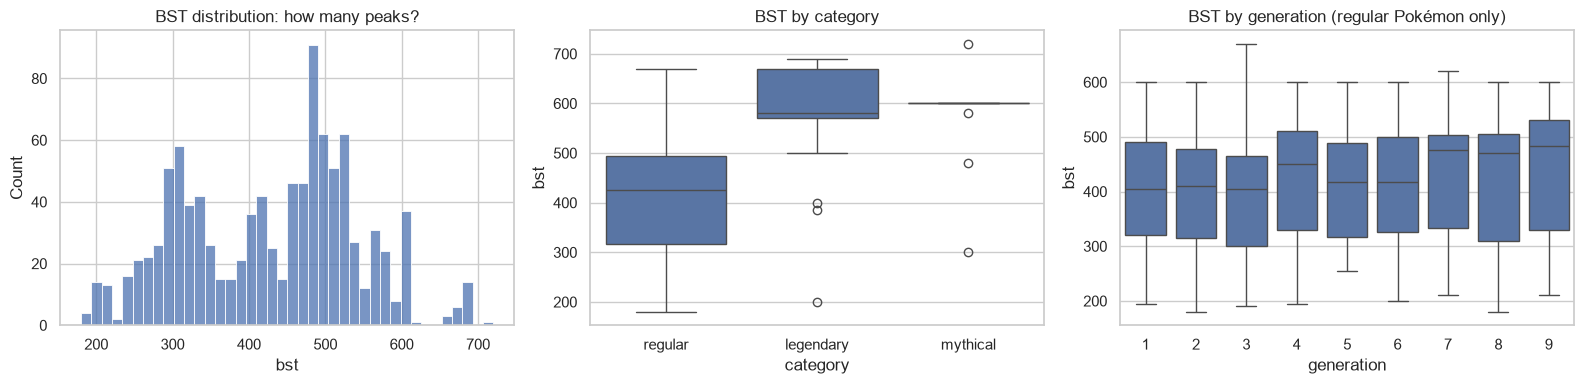

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["bst"], bins=40, ax=axes[0])
axes[0].set_title("BST distribution: how many peaks?")

sns.boxplot(data=df, x="category", y="bst", order=["regular", "legendary", "mythical"], ax=axes[1])
axes[1].set_title("BST by category")

sns.boxplot(data=df[df["category"] == "regular"], x="generation", y="bst", ax=axes[2])
axes[2].set_title("BST by generation (regular Pokémon only)")
plt.tight_layout()

df.groupby("category")["bst"].describe().round(0)

## 4. How do the stats relate to each other?

Left: raw stats (what Representation A clusters on).
Right: relative stats, stat / BST (Representation B).

Relative stats always sum to 1, so if one share goes up, the others must go down on average. With 6 parts, the average correlation is forced toward **−1 / (6 − 1) = −0.2** even if nothing interesting is going on. Only correlations clearly below or above that baseline mean something.

Average off-diagonal correlation, raw:      0.32
Average off-diagonal correlation, relative: -0.2

Each raw stat's correlation with BST:
hp            0.66
attack        0.71
defense       0.63
sp_attack     0.70
sp_defense    0.70
speed         0.55
dtype: float64


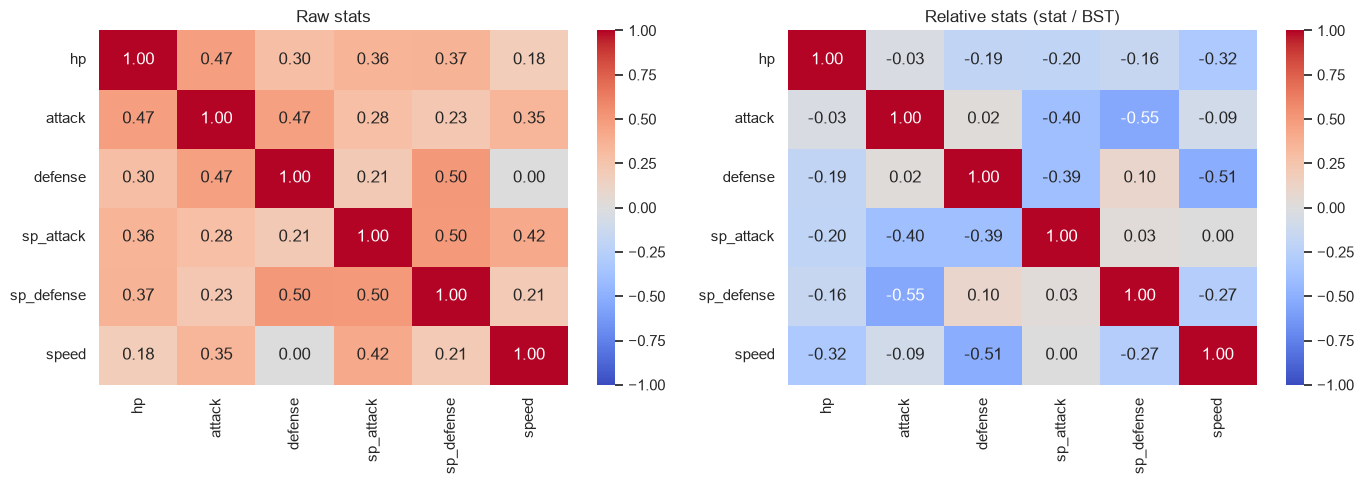

In [24]:
relative = df[STAT_COLS].div(df["bst"], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title in [(axes[0], df[STAT_COLS], "Raw stats"), (axes[1], relative, "Relative stats (stat / BST)")]:
    sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(title)
plt.tight_layout()

off_diag = lambda c: c.where(~np.eye(len(c), dtype=bool)).stack()
print("Average off-diagonal correlation, raw:     ", round(off_diag(df[STAT_COLS].corr()).mean(), 2))
print("Average off-diagonal correlation, relative:", round(off_diag(relative.corr()).mean(), 2))
print("\nEach raw stat's correlation with BST:")
print(df[STAT_COLS].corrwith(df["bst"]).round(2))

## 5. Evolution stage: the hidden variable behind BST

If the two BST peaks are 'still evolving' vs 'fully evolved', then any comparison across groups must check whether the groups have different shares of unevolved Pokémon.

Share NOT fully evolved, by generation:
{1: 0.56, 2: 0.52, 3: 0.47, 4: 0.36, 5: 0.49, 6: 0.47, 7: 0.36, 8: 0.38, 9: 0.33}


,all regular,fully evolved only
generation,,
1,405.0,490.0
2,410.0,482.5
3,405.0,466.0
4,450.0,500.0
5,418.0,490.0
6,417.0,500.0
7,475.5,492.5
8,470.0,502.0
9,483.0,520.5


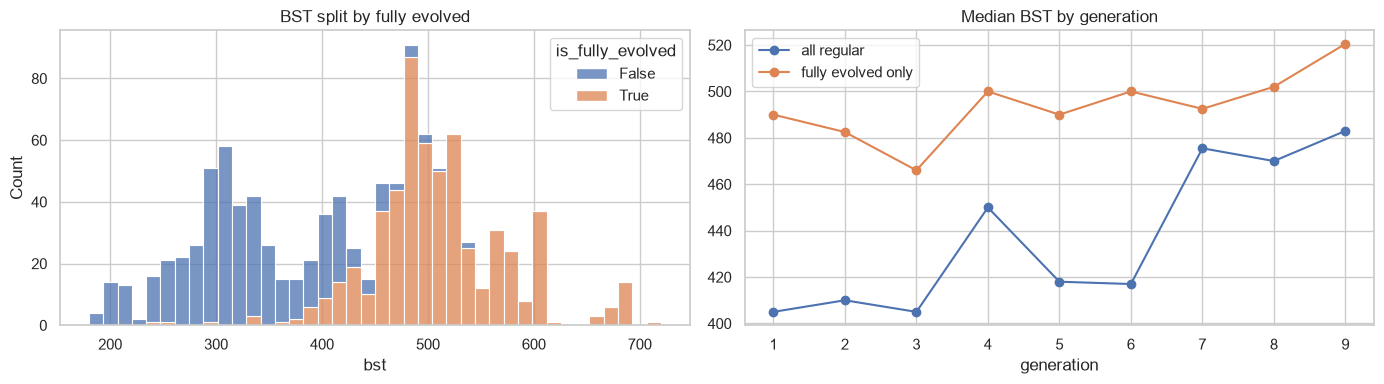

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=df, x="bst", hue="is_fully_evolved", bins=40, multiple="stack", ax=axes[0])
axes[0].set_title("BST split by fully evolved")

regular = df[df["category"] == "regular"]
by_gen = pd.DataFrame({
    "all regular": regular.groupby("generation")["bst"].median(),
    "fully evolved only": regular[regular["is_fully_evolved"]].groupby("generation")["bst"].median(),
})
by_gen.plot(marker="o", ax=axes[1], title="Median BST by generation")
plt.tight_layout()

print("Share NOT fully evolved, by generation:")
print((1 - df.groupby("generation")["is_fully_evolved"].mean()).round(2).to_dict())
by_gen

### Explanation

The dataset contains 1,025 Pokémon, with most classified as regular rather than legendary or mythical. The six base stats have different distributions, and some have right-skewed distributions, meaning a smaller number of Pokémon have exceptionally high values.

Base Stat Total (BST) varies considerably across Pokémon. Legendary and mythical Pokémon generally have higher BSTs than regular Pokémon. However, evolution stage also plays an important role in explaining BST differences.

One interesting finding is the effect of power creep across generations. The median BST of regular Pokémon increases from 405 in Generation 1 to 483 in Generation 9. However, later generations also contain a larger share of fully evolved Pokémon. When comparing only fully evolved Pokémon, the median increases from 490 to 520.5, suggesting that evolution stage explains part, but not all, of the increase.

The raw stats are correlated because Pokémon with higher overall BSTs generally have higher individual stats. Relative stats (each stat divided by BST) remove much of this overall strength difference. This allows us to compare how Pokémon distribute their stats rather than simply comparing how strong they are.